# Classification de l'espèce d'un iris : KNN vs Arbre de décision

**Durée estimée : 1h**

## Mise en situation
Vous êtes data scientist chez **FloraLab**, un laboratoire de botanique. La direction veut un outil qui reconnaît **automatiquement l'espèce d'un iris** (Setosa, Versicolor, Virginica) à partir de quatre mesures, sans expert.


## Comment utiliser ce notebook
- Chaque section contient une **explication** (cellule texte) suivie d'une **cellule de code à compléter**.
- Les lignes `# TODO` indiquent ce qu'il faut écrire, avec un **indice** sur la fonction à utiliser.
- Les cellules **Interprétation** sont à remplir avec vos propres mots : c'est ce qui est évalué en plus du code.
- Exécutez les cellules **dans l'ordre**.

## 0. Imports et configuration
*Cette cellule est déjà remplie. Ajoutez des imports si nécessaire.*

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Exploration et analyse des données (EDA)

### 1.1 Chargement et structure
**But :** comprendre la forme.
**À faire :** llire le dataset, puis afficher `head()`, `shape`, `info()` et `describe()`.



In [7]:
df = sns.load_dataset("iris")
# TODO 1 : afficher head(), shape, info() et describe()

df.head()

# df.shape

# df.info()

# df.describe()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


### 1.2 Types de variables, valeurs manquantes et doublons
**But :** repérer les problèmes de qualité.
**À faire :** identifier variables numériques et catégorielles, compter les valeurs manquantes et les doublons, vérifier qu'aucune mesure n'est négative ou nulle.


In [25]:
# TODO : types, valeurs manquantes, doublons, valeurs impossibles

df.dtypes

# df.isna().sum()

# df.duplicated()


sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

### 1.3 Équilibre des classes
**But :** savoir si l'accuracy sera une métrique fiable.
**À faire :** compter le nombre de fleurs par espèce et l'afficher dans un graphique en barres.


<Axes: xlabel='species', ylabel='count'>

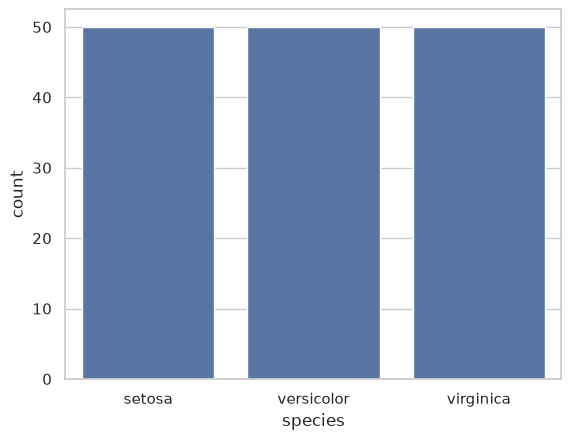

In [31]:
# TODO : value_counts + countplot ou graphique en barres

df['species'].value_counts()

sns.countplot(
    data=df,x=df['species']
)

### 1.4 Distributions des variables
**But :** comprendre la forme de chaque mesure.
**À faire :** tracer un histogramme et un boxplot pour une variable(s) numérique(s).


<Axes: xlabel='sepal_length', ylabel='Count'>

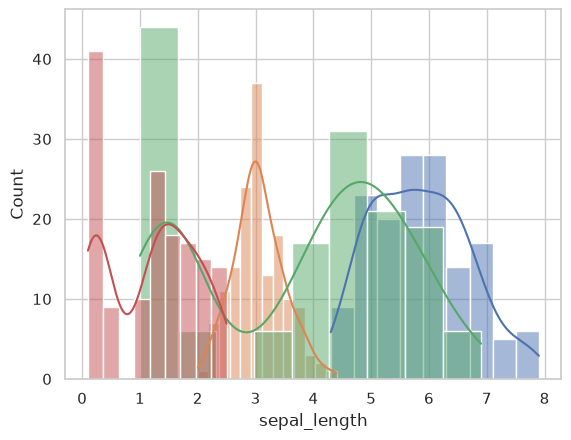

In [21]:
# TODO : histogrammes
# TODO : boxplots par espèce

sns.histplot(
    data=df,
    x=df['sepal_length'],
    kde=0.5
)
sns.histplot(
    data=df,
    x=df['sepal_width'],
    kde=0.5
)
sns.histplot(
    data=df,
    x=df['petal_length'],
    kde=0.5
)
sns.histplot(
    data=df,
    x=df['petal_width'],
    kde=0.5
)



### 1.5 Corrélations
**But :** repérer les variables redondantes.
**À faire :** calculer la matrice de corrélation des 4 mesures et l'afficher en heatmap.


<Axes: >

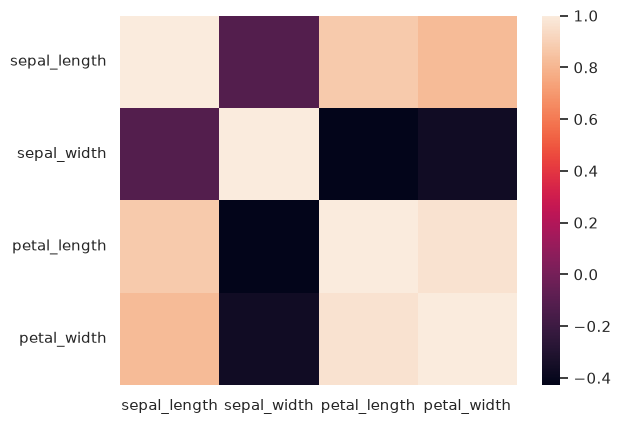

In [29]:
# TODO : matrice de corrélation + heatmap
df.select_dtypes(include='float64').corr()
sns.heatmap(data=df.select_dtypes(include='float64').corr())


## 2. Nettoyage des données
**But :** obtenir un jeu de données fiable.
**À faire :**
1. Traiter les valeurs manquantes (s'il y en a).
2. Supprimer les doublons **seulement si c'est justifié**.
3. Corriger les valeurs impossibles.
4. Vérifier la qualité après nettoyage (shape, doublons, valeurs manquantes).


In [30]:
# TODO : nettoyage (doublons, valeurs manquantes, incohérences)
# TODO : vérification après nettoyage

df.dropna()

# i would delete the dups and nan since i want data to be unique for the model to pick the patarens in more rich data rather then similar paterns  

df.drop_duplicates()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


**Justification de vos décisions de nettoyage :**

...

## 3. Préparation des données
**But :** séparer ce qu'on veut prédire de ce qui sert à prédire.
**À faire :**
- Définir `y` (la cible : l'espèce).
- Définir `X` (les 4 mesures).
- Lister les variables numériques, nominales et ordinales.
- Écarter les identifiants ou variables non pertinentes.

In [37]:
# TODO : définir y
y = df['species']
# TODO : définir X  
x = df.drop(columns='species')
# TODO : créer la liste num_features (variables numériques)




## 4. Séparation Train / Test
**But :** garder un jeu de test totalement indépendant pour l'évaluation finale.
**À faire :** séparer en 80 % / 20 % avec `random_state` et `stratify=y`, puis vérifier la répartition des espèces dans chaque ensemble.

> Le split se fait **avant** tout apprentissage de transformation (sinon : fuite de données).

In [ ]:
# TODO : X_train, X_test, y_train, y_test = train_test_split(...)
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    random_state=RANDOM_STATE,
    stratify=y
)
# TODO : afficher la répartition des espèces dans y_train et y_test
display(X_train, X_test)

,sepal_length,sepal_width,petal_length,petal_width
130,7.4,2.8,6.1,1.9
122,7.7,2.8,6.7,2.0
81,5.5,2.4,3.7,1.0
71,6.1,2.8,4.0,1.3
89,5.5,2.5,4.0,1.3
...,...,...,...,...
49,5.0,3.3,1.4,0.2
21,5.1,3.7,1.5,0.4
45,4.8,3.0,1.4,0.3
92,5.8,2.6,4.0,1.2


,sepal_length,sepal_width,petal_length,petal_width
42,4.4,3.2,1.3,0.2
56,6.3,3.3,4.7,1.6
99,5.7,2.8,4.1,1.3
53,5.5,2.3,4.0,1.3
38,4.4,3.0,1.3,0.2
85,6.0,3.4,4.5,1.6
134,6.1,2.6,5.6,1.4
141,6.9,3.1,5.1,2.3
107,7.3,2.9,6.3,1.8
132,6.4,2.8,5.6,2.2


## 5. Prétraitement
**But :** préparer les transformations (sans encore les apprendre).
**À faire :**
- Créer un `ColumnTransformer` qui applique sur les variables numériques : `SimpleImputer(strategy='median')` puis `StandardScaler()`.
- Justifier l'absence d'`OneHotEncoder` et d'`OrdinalEncoder`.

In [54]:
# TODO : numeric_transformer = Pipeline([...])

# TODO : preprocessor = ColumnTransformer([...])
preprocessor = ColumnTransformer(transformers=[
    ('ir1',StandardScaler(),['sepal_length','sepal_width','petal_length','petal_width'])
],remainder='passthrough')

## 6. Construction des pipelines
**But :** enchaîner prétraitement + modèle dans un seul objet, pour éviter toute fuite de données pendant la validation croisée.
**À faire :** créer ** le pipeline ** :
- `pipe_knn` : preprocessor + `KNeighborsClassifier()`

> Dans un `Pipeline`, donnez des noms aux étapes (par ex. `'prep'` et `'model'`) : vous en aurez besoin pour la grille d'hyperparamètres (`model__n_neighbors`).

In [55]:
# TODO : pipe_knn = Pipeline([...])
m_knn = KNeighborsClassifier()

pipe_knn = Pipeline([
    ('prep',preprocessor),
    ('model', m_knn)
    ])

## 7. Entraînement
**But :** obtenir une première version du modèle avec les hyperparamètres par défaut.

- **Algorithme 1 : KNN** — classe une fleur selon ses voisins les plus proches (modèle de référence).

**À faire :** entraîner le pipeline sur `X_train`, `y_train` et afficher l'accuracy sur le train.

In [60]:
# TODO : fit de pipe_knn
pipe_knn.fit(X_train, y_train)
# TODO : afficher le score train de chacun (.score)
pipe_knn.score(X_train, y_train)


0.9821428571428571

## 8. Validation croisée
**But :** estimer la performance de façon fiable.
**À faire :**
- Créer `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)`.
- Calculer les scores de chaque pipeline avec `cross_val_score` (métrique `accuracy`, puis `f1_macro`).
- Afficher la **moyenne** des scores.


In [62]:
# TODO : cv = StratifiedKFold(...)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# TODO : scores accuracy et f1_macro pour pipe_knn

scores_accuracy = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring="accuracy")
scores_f1_macro = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring="f1_macro")

# TODO : afficher moyenne

print(f"Moyenne accuracy : {scores_accuracy.mean()}")

print(f"Moyenne F1 macro : {scores_f1_macro.mean()}")

Moyenne accuracy : 0.9556661925082978
Moyenne F1 macro : 0.9549973161567364


## 9. Optimisation des hyperparamètres (GridSearchCV)
**But :** trouver les meilleurs réglages.
**À faire :** définir une grille pour ton pipeline, lancer `GridSearchCV(..., cv=cv, scoring='f1_macro')` et afficher `best_params_` et `best_score_`.

Grilles suggérées :
- **KNN** : `model__n_neighbors` (2 à 5), `model__weights` (`uniform`, `distance`), `model__p` (1, 2).
> Le préfixe `model__` correspond au nom de l'étape dans votre pipeline.
> Le GridSearch ne doit utiliser que `X_train` et `y_train`.

In [64]:
# TODO : param_grid_knn
param_grid_knn = {
    "model__n_neighbors": [2, 3, 4, 5],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

# TODO : grid_knn = GridSearchCV(...) puis fit sur le train
grid_knn = GridSearchCV(
    pipe_knn,
    param_grid=param_grid_knn,
    cv=cv,
    scoring="f1_macro"
 )
grid_knn.fit(X_train, y_train)

# TODO : afficher best_params_ et best_score_
print(grid_knn.best_params_)
print(grid_knn.best_score_)

{'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'uniform'}
0.9635169482512477


## 10. Évaluation sur le jeu de test
**But :** mesurer la performance réelle sur des données jamais vues.
**À faire :** pour chaque meilleur modèle (`best_estimator_`) :
1. Prédire sur `X_test`.
2. Calculer accuracy, précision (macro), rappel (macro) et F1 (macro).
3. Afficher la **matrice de confusion** et le `classification_report`.
4. Donner les valeurs ( TP , FP , TN , FN) pour chaque classe .

Rappel des métriques :
- **Accuracy** : proportion de fleurs bien classées.
- **Précision** : parmi les fleurs prédites d'une espèce, combien le sont vraiment.
- **Rappel** : parmi les fleurs réellement d'une espèce, combien sont retrouvées.
- **F1 macro** : moyenne du F1 des trois espèces, à égalité.

> Le jeu de test ne doit servir qu'ici, une seule fois.

In [ ]:
# TODO : best_knn = grid_knn.best_estimator_
best_knn = grid_knn.best_estimator_
# TODO : prédictions sur X_test
y_pred = best_knn.predict(X_test)
# TODO : métriques (accuracy, precision, recall, f1 avec average='macro')

# TODO : matrices de confusion (ConfusionMatrixDisplay.from_estimator)

# TODO : classification_report
